# Lab 10: Perceptron from Scratch

MLPR, Semester 4. A single perceptron with a step activation and the perceptron learning rule, written in NumPy. It separates two Gaussian classes of 250 points each.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score

np.random.seed(0)
class1 = np.random.multivariate_normal([2, 2], [[0.9, -0.0255], [-0.0255, 0.9]], 250)
class2 = np.random.multivariate_normal([5, 5], [[0.5, 0], [0, 0.3]], 250)
X = np.vstack((class1, class2))
y = np.hstack((np.zeros(250), np.ones(250)))
X_bias = np.hstack((np.ones((X.shape[0], 1)), X))   # bias input of 1
X_train, X_test, y_train, y_test = train_test_split(X_bias, y, test_size=0.2, random_state=0)


def step_function(x):
    return 1 if x >= 0 else 0


def perceptron_train(X, y, lr=0.1, max_epochs=1000):
    weights = np.zeros(X.shape[1])
    for epoch in range(max_epochs):
        errors = 0
        for xi, target in zip(X, y):
            update = lr * (target - step_function(xi @ weights))
            weights += update * xi
            errors += int(update != 0)
        if errors == 0:            # every training point classified correctly
            print(f"Converged after {epoch + 1} epochs")
            break
    return weights


def predict(X, weights):
    return np.array([step_function(xi @ weights) for xi in X])


weights = perceptron_train(X_train, y_train)
y_pred = predict(X_test, weights)
print("weights (bias, w1, w2):", np.round(weights, 3))
print(f"test accuracy: {accuracy_score(y_test, y_pred):.3f}")

Converged after 4 epochs
weights (bias, w1, w2): [-3.5    0.456  0.509]
test accuracy: 1.000


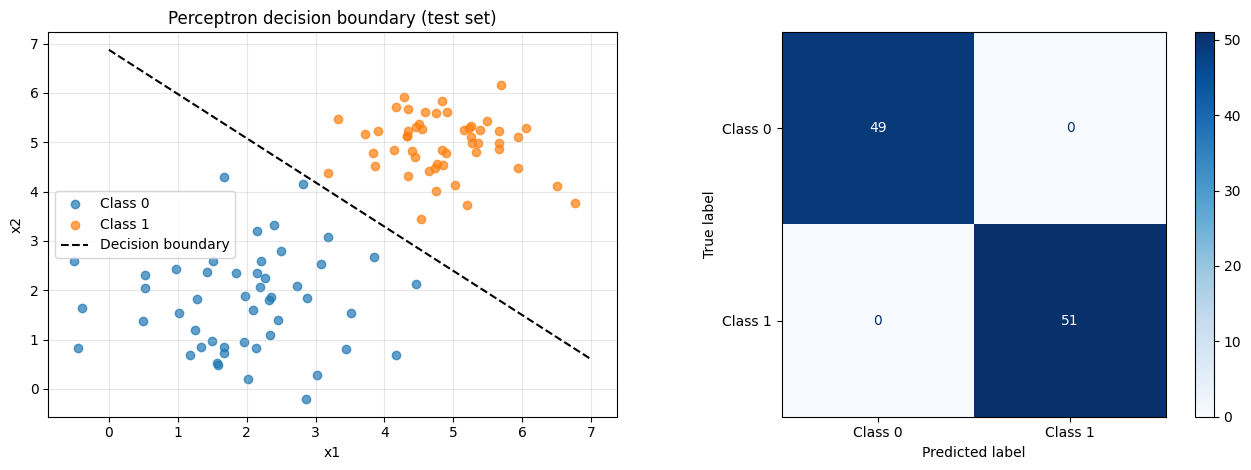

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for k in (0, 1):
    axes[0].scatter(X_test[y_test == k][:, 1], X_test[y_test == k][:, 2], label=f"Class {k}", alpha=0.7)
x_vals = np.linspace(0, 7, 100)
axes[0].plot(x_vals, -(weights[0] + weights[1] * x_vals) / weights[2], "k--", label="Decision boundary")
axes[0].set_xlabel("x1"); axes[0].set_ylabel("x2"); axes[0].set_title("Perceptron decision boundary (test set)")
axes[0].legend(); axes[0].grid(alpha=0.3)
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["Class 0", "Class 1"]).plot(ax=axes[1], cmap="Blues")
plt.tight_layout()
plt.savefig("images/lab10_perceptron.png")
plt.show()

## Report

1. **Parallels between biological and artificial neural networks:** both are made of many interconnected units (neurons or nodes); both learn by adjusting connection strengths (synapses or weights); and both units "fire" only when the combined input passes a threshold (an activation function).
2. **McCulloch-Pitts neuron (1943):** a binary threshold unit that outputs 1 when the weighted sum of its inputs exceeds a threshold. Its limitations: it can only solve linearly separable problems (not XOR), and its weights are fixed by hand rather than learned.
3. **Perceptron learning:** for each sample, predict with the current weights; if the prediction is wrong, update `w = w + lr * (target - prediction) * x`. Repeat until no training errors remain or a maximum number of epochs is reached.
4. **Activation functions:** step, output {0, 1}; sigmoid 1 / (1 + e^-x), output (0, 1); tanh, output (-1, 1); ReLU max(0, x), output [0, infinity).
5. **XOR:** XOR is not linearly separable, so no single straight line (a single perceptron) can separate it. A multi-layer network with a hidden layer and non-linear activations can (see Lab 11).